In [1]:
%matplotlib widget

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.special as sp
import math as math

In [3]:
def factorial(x):
    return(sp.factorial(x, exact=True))

def multi(N, up):
    return(factorial(N)/(factorial(up)*factorial(N-up)))

def logArray(array):
    return([math.log(x) for x in array])

In [4]:
pd.set_option('display.max_rows', None)

In [5]:
N = 100

df = pd.DataFrame({'up':range(0,N+1)})

df['down'] = N-df['up']

df['multi'] = [multi(N, up) for up in df['up']]

df['S/k'] = logArray(df['multi'])

df['U/uB'] = N - 2*df['up']

df['kT/uB'] = np.gradient(df['U/uB'])/np.gradient(df['S/k'])

df['C/Nk'] = np.gradient(df['U/uB'])/np.gradient(df['kT/uB'])/N

/tmp/ipykernel_352197/82906899.py:13: RuntimeWarning: divide by zero encountered in divide
  df['kT/uB'] = np.gradient(df['U/uB'])/np.gradient(df['S/k'])


In [6]:
df

,up,down,multi,S/k,U/uB,kT/uB,C/Nk
0,0,100,1.000000e+00,0.000000,100,-0.434294,0.557124
1,1,99,1.000000e+02,4.605170,98,-0.470193,0.373483
2,2,98,4.950000e+03,8.507143,96,-0.541394,0.309889
3,3,97,1.617000e+05,11.993498,94,-0.599271,0.364569
4,4,96,3.921225e+06,15.181915,92,-0.651113,0.398435
5,5,95,7.528752e+07,18.136825,90,-0.699664,0.420058
6,6,94,1.192052e+09,20.898942,88,-0.746338,0.433229
7,7,93,1.600756e+10,23.496327,86,-0.791994,0.440136
8,8,92,1.860879e+11,25.949485,84,-0.837219,0.442208
9,9,91,1.902232e+12,28.274049,82,-0.882449,0.440458


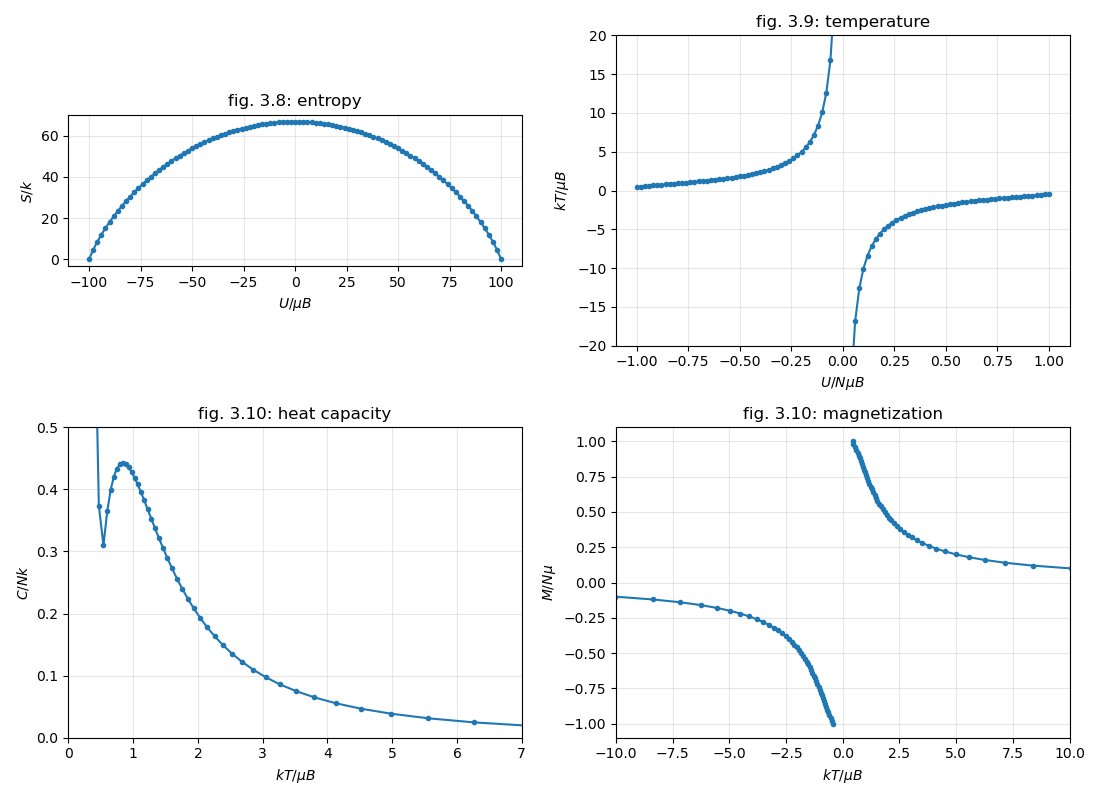

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# figure 3.8: entropy vs. energy
ax[0,0].plot(df['U/uB'], df['S/k'], '.-')
ax[0,0].set(xlabel=r'$U/\mu B$', ylabel=r'$S/k$',
            title='fig. 3.8: entropy', aspect='equal')

# figure 3.9: temperature vs. energy
ax[0,1].plot(df['U/uB']/N, df['kT/uB'], '.-')
ax[0,1].set(xlabel=r'$U/N\mu B$', ylabel=r'$kT/\mu B$',
            title='fig. 3.9: temperature', ylim=(-20, 20))

# figure 3.10: heat capacity vs. temperature
positive = df['kT/uB'] > 0
ax[1,0].plot(df.loc[positive, 'kT/uB'],
             df.loc[positive, 'C/Nk'], '.-')
ax[1,0].set(xlabel=r'$kT/\mu B$', ylabel=r'$C/Nk$',
            title='fig. 3.10: heat capacity',
            xlim=(0, 7), ylim=(0, 0.5))

# figure 3.10: magnetization vs. temperature
ax[1,1].plot(df['kT/uB'], -df['U/uB']/N, '.-')
ax[1,1].set(xlabel=r'$kT/\mu B$', ylabel=r'$M/N\mu$',
            title='fig. 3.10: magnetization',
            xlim=(-10, 10), ylim=(-1.1, 1.1))

for a in ax.flat:
    a.grid(alpha=0.3)

plt.tight_layout()
plt.show()
